# Math 465 Fall 2026

## Module 2. Demo 3: PCA when the dimension exceeds the sample size

Xiuyuan Cheng  
xiuyuan.cheng@duke.edu

# The $n<p$ case 

This section studies the case $n<p$. We simulate $n=800$ observations in $p=1000$ dimensions, but plant only three informative directions. Ordinary PCA will show that:

- the sample covariance matrix is singular when $n<p$;
- singularity does not prevent us from estimating a few leading principal components;
- the first three PCA modes recover the planted signal subspace and reveal the cluster structure.

The same data model is used again in Module 4, where ordinary PCA will be the reference answer for randomized PCA. A second example uses a pure-noise matrix of the same size and compares its covariance spectrum with the Marchenko--Pastur law.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import qr, subspace_angles
from scipy.linalg.blas import dgemm
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

### Why $n<p$ makes the sample covariance singular

Put the centered observations into $X_c\in\mathbb{R}^{n\times p}$. The sample covariance is

$$S=\frac{1}{n}X_c^TX_c\in\mathbb{R}^{p\times p}.$$

Centering gives $\operatorname{rank}(X_c)\leq n-1$, and therefore

$$\operatorname{rank}(S)\leq n-1<p.$$

Thus $S$ cannot be inverted and at least $p-n+1$ of its eigenvalues are zero. 
However, PCA does not require $S^{-1}$. 
We will show that in some situations, the (truncated) SVD of $X_c$ can still identify its leading singular directions. This is useful when the information is approximately low-rank.

### Simulated high-dimensional data with a rank-three signal

Let $Z$ contain clustered observations in three latent coordinates. Embed them into $p$ observed coordinates using a matrix $Q$ with orthonormal columns, and then add small independent noise:

$$X = ZQ^T + \sigma E,\qquad Z\in\mathbb{R}^{n\times3},\quad Q\in\mathbb{R}^{p\times3}.$$

The noiseless part $X_{\mathrm{signal}}=ZQ^T$ has rank at most three. The observed matrix $X$ is numerically full rank, but its informative subspace is still only three-dimensional.

In [2]:
# These parameters and this construction are reused in the Module 4 demo.
n_samples = 800
n_features = 1000
signal_rank = 3
noise_level = 0.03
random_state = 120

rng = np.random.default_rng(random_state)

Z, labels = make_blobs(
    n_samples=n_samples, n_features=signal_rank, centers=5,
    cluster_std=1.0, random_state=random_state
)
Z = StandardScaler().fit_transform(Z)

# Orthonormal embedding of the three latent coordinates into R^p.
Q_signal = qr(
    rng.normal(size=(n_features, signal_rank)), mode='economic'
)[0]
X_signal = dgemm(alpha=1.0, a=Z, b=Q_signal.T)
X = X_signal + noise_level * rng.normal(size=(n_samples, n_features))

print('observed data matrix X:', X.shape)
print('latent coordinate matrix Z:', Z.shape)
print('n < p:', n_samples < n_features)
print('maximum rank after centering:', min(n_samples - 1, n_features))
print('guaranteed zero covariance eigenvalues:', n_features - n_samples + 1)

observed data matrix X: (800, 1000)
latent coordinate matrix Z: (800, 3)
n < p: True
maximum rank after centering: 799
guaranteed zero covariance eigenvalues: 201


The cluster labels are used only to color plots; PCA never sees them. The three latent coordinates below are the "true information" planted in the data.

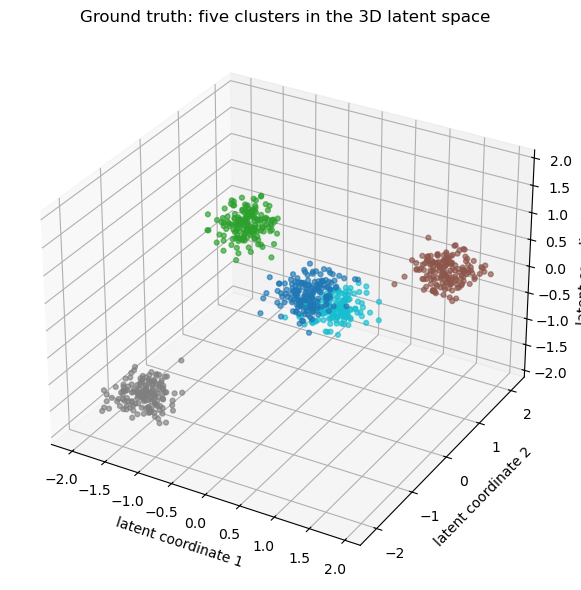

In [3]:
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(Z[:, 0], Z[:, 1], Z[:, 2], c=labels, s=12,
           cmap='tab10', alpha=0.65)
ax.set(xlabel='latent coordinate 1', ylabel='latent coordinate 2',
       zlabel='latent coordinate 3',
       title='Ground truth: five clusters in the 3D latent space')
plt.tight_layout()
plt.show()

### Ordinary PCA using the full SVD solver

We now fit PCA directly to the $800\times1000$ observed matrix. Scikit-learn centers $X$ and computes its SVD. No inverse of the singular $1000\times1000$ sample covariance matrix is needed.

In [4]:
pca_full = PCA(svd_solver='full')
scores_full = pca_full.fit_transform(X)

print('number of singular values returned:', len(pca_full.singular_values_))
print('first six singular values:')
print(np.round(pca_full.singular_values_[:10], 3))
print('variance explained by PC1--PC3:',
      f'{pca_full.explained_variance_ratio_[:3].sum():.1%}')

number of singular values returned: 800
first six singular values:
[40.938 25.501  8.916  1.782  1.771  1.766  1.759  1.758  1.746  1.737]
variance explained by PC1--PC3: 77.1%


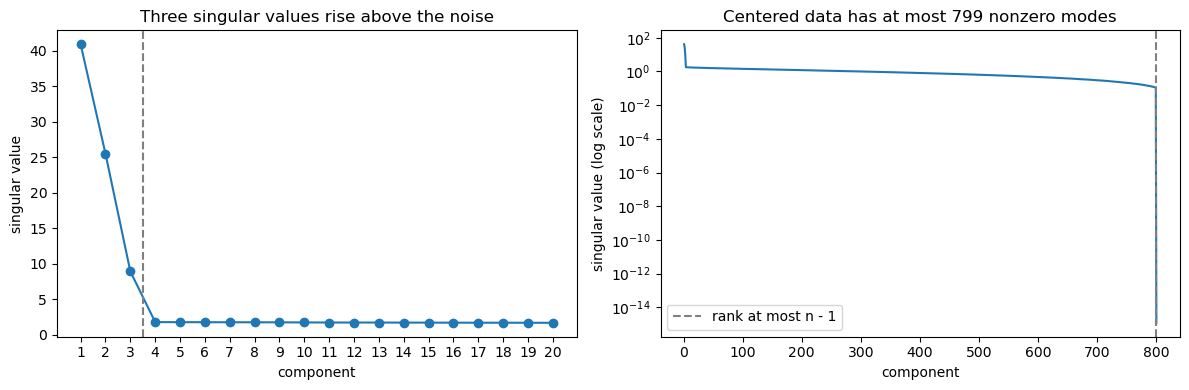

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

component_index = np.arange(1, 21)
axes[0].plot(component_index, pca_full.singular_values_[:20], 'o-')
axes[0].axvline(signal_rank + 0.5, color='gray', linestyle='--')
axes[0].set(xticks=np.arange(1, 21), xlabel='component',
            ylabel='singular value',
            title='Three singular values rise above the noise')

axes[1].semilogy(np.arange(1, len(pca_full.singular_values_) + 1),
                 pca_full.singular_values_)
axes[1].axvline(n_samples - 1, color='gray', linestyle='--',
                label='rank at most n - 1')
axes[1].set(xlabel='component', ylabel='singular value (log scale)',
            title='Centered data has at most 799 nonzero modes')
axes[1].legend()

plt.tight_layout()
plt.show()

There are three dominant singular values, exactly as suggested by the data model. The remaining modes mostly describe noise. Notice also the final numerical zero caused by centering. If we explicitly formed the $1000\times1000$ covariance matrix, it would have another 200 zero eigenvalues that are not listed by this thin SVD.

### Do the first three PCA modes recover the true information?

The first three score coordinates give one basis for the estimated signal space. That basis can be rotated or reflected relative to the original latent coordinates, so individual axes need not match. What should survive is the three-dimensional geometry and its cluster structure.

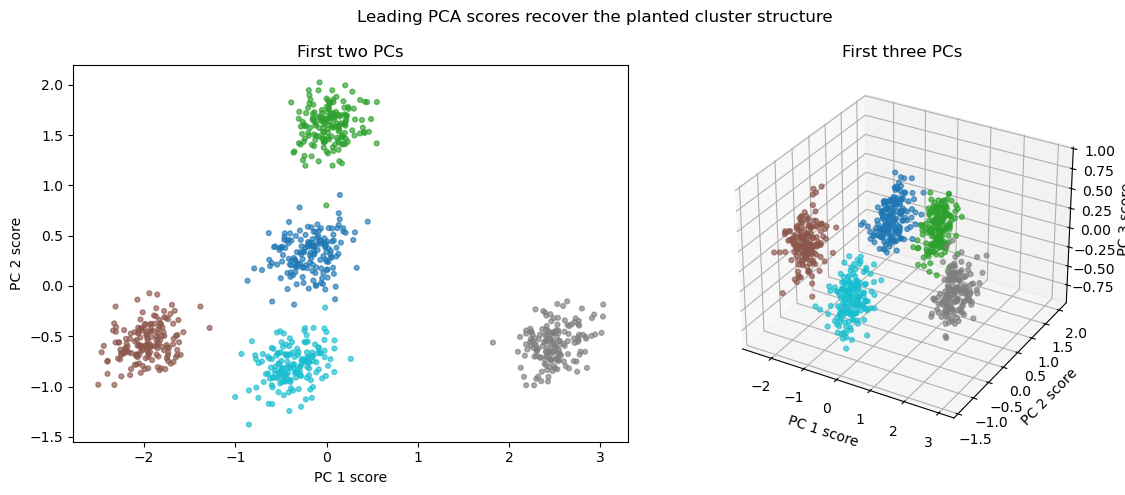

In [6]:
fig = plt.figure(figsize=(12, 5))

ax = fig.add_subplot(121)
ax.scatter(scores_full[:, 0], scores_full[:, 1], c=labels,
           s=12, cmap='tab10', alpha=0.65)
ax.set(xlabel='PC 1 score', ylabel='PC 2 score',
       title='First two PCs')

ax = fig.add_subplot(122, projection='3d')
ax.scatter(scores_full[:, 0], scores_full[:, 1], scores_full[:, 2],
           c=labels, s=12, cmap='tab10', alpha=0.65)
ax.set(xlabel='PC 1 score', ylabel='PC 2 score', zlabel='PC 3 score',
       title='First three PCs')

fig.suptitle('Leading PCA scores recover the planted cluster structure')
plt.tight_layout()
plt.show()

We know the planted three-dimensional feature subspace: it is the column space of $Q$. The estimated feature subspace is spanned by the first three PCA loading vectors. Principal angles compare these subspaces without requiring their individual basis vectors to have matching signs or order. Angles near zero mean good recovery.

In [7]:
estimated_signal_basis = pca_full.components_[:signal_rank].T
angles_degrees = np.degrees(
    subspace_angles(Q_signal, estimated_signal_basis)
)

print('principal angles between true and PCA subspaces (degrees):')
print(np.round(angles_degrees, 2))

principal angles between true and PCA subspaces (degrees):
[6.41 2.15 1.36]


### Cumulative signal information retained

Because the planted signal $X_{\mathrm{signal}}$ is known in this simulation, we can measure directly how much of its centered squared energy is retained by the first $i$ estimated PCs:

$$R_i=\frac{\sum_{j=1}^i\|X_{\mathrm{signal},c}v_j\|_2^2}{\|X_{\mathrm{signal},c}\|_F^2},\qquad i=1,2,3.$$

Here $v_j$ is the $j$th PCA loading estimated from the noisy observations. Thus $R_i$ measures recovery of the true information, rather than total noisy-data variance explained.

In [8]:
X_signal_centered = X_signal - X_signal.mean(axis=0)
leading_loadings = pca_full.components_[:signal_rank]

# Scores of the true signal on the PCs estimated from noisy data.
signal_scores = np.einsum(
    'np,ip->ni', X_signal_centered, leading_loadings, optimize=False
)
energy_by_pc = np.sum(signal_scores ** 2, axis=0)
total_signal_energy = np.sum(X_signal_centered ** 2)
cumulative_signal_retained = np.cumsum(energy_by_pc) / total_signal_energy

print('True signal information retained')
for i, retained in enumerate(cumulative_signal_retained, start=1):
    print(f'  first {i} PC(s): {retained:.2%}')

True signal information retained
  first 1 PC(s): 69.75%
  first 2 PC(s): 96.72%
  first 3 PC(s): 99.88%


### What we see

- Since $n=800<p=1000$, the sample covariance matrix is singular; PCA still computes meaningful leading directions.
- The first three singular values separate clearly from the noise modes, matching the planted rank-three model.
- The first three PCA scores reveal the five clusters even though the observations live in 1000 dimensions and the labels were not used by PCA.
- The small principal angles show that the recovered three-dimensional loading subspace is close to the true signal subspace.
- Projection onto the first PC, first two PCs, and first three PCs retains progressively more of the planted signal; the first three retain nearly all, but not exactly all, of it.

The lesson is not that $n<p$ is harmless for every estimation problem. It is that when the scientific information is concentrated in a few strong modes, leading low-rank PCA can still be useful even though the full covariance matrix is singular.

# PCA of pure high-dimensional noise

Now keep the same dimensions, $n=800$ and $p=1000$, but remove the low-rank signal. Let every entry of $X_{\mathrm{noise}}$ be an independent $\mathcal{N}(0,1)$ random variable. We study the eigenvalues of

$$S_{\mathrm{noise}}=\frac{1}{n}X_{\mathrm{noise},c}^T X_{\mathrm{noise},c}.$$

There are no preferred or uniquely determined population principal directions because the population covariance is $I_p$. Nevertheless, the sample eigenvalues are spread over a nontrivial interval because both $n$ and $p$ are large.

In [9]:
noise_rng = np.random.default_rng(2026)
X_noise = noise_rng.normal(size=(n_samples, n_features))
X_noise_centered = X_noise - X_noise.mean(axis=0)

# If s_j are the singular values of X_noise_centered, then s_j^2 / n
# are the nonzero eigenvalues of S_noise = X_noise_centered.T X_noise_centered / n.
_, singular_values_noise, noise_loadings = np.linalg.svd(
    X_noise_centered, full_matrices=False
)
tolerance = (
    singular_values_noise[0] * max(X_noise_centered.shape)
    * np.finfo(float).eps
)
positive_eigenvalues = (
    singular_values_noise[singular_values_noise > tolerance] ** 2
    / n_samples
)
number_of_zeros = n_features - len(positive_eigenvalues)
all_eigenvalues = np.concatenate([
    np.zeros(number_of_zeros), positive_eigenvalues
])

print('shape of pure-noise matrix:', X_noise.shape)
print('positive eigenvalues:', len(positive_eigenvalues))
print('zero eigenvalues:', number_of_zeros)

shape of pure-noise matrix: (800, 1000)
positive eigenvalues: 799
zero eigenvalues: 201


### Optional: Marchenko--Pastur distribution for eigenvalues

Let $\gamma=p/n=1.25$. For unit-variance noise, the Marchenko--Pastur continuous spectrum has support

$$\lambda_-=(1-\sqrt{\gamma})^2,\qquad \lambda_+=(1+\sqrt{\gamma})^2.$$

Because $\gamma>1$, the spectral distribution of the $p\times p$ covariance also has an atom of mass $1-1/\gamma$ at zero. Here centering reduces the rank by one more, giving exactly $p-n+1=201$ zero eigenvalues.

The histogram below is conditional on positive eigenvalues, so the continuous Marchenko--Pastur density is renormalized to integrate to one.

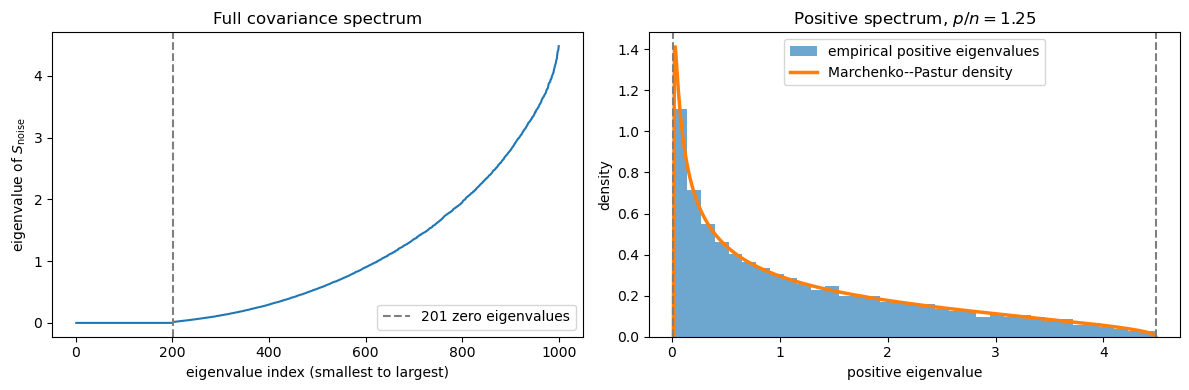

MP support: [0.014, 4.486]
empirical positive range: [0.015, 4.481]


In [10]:
gamma = n_features / n_samples
lambda_minus = (1 - np.sqrt(gamma)) ** 2
lambda_plus = (1 + np.sqrt(gamma)) ** 2

lambda_grid = np.linspace(lambda_minus, lambda_plus, 500)
mp_density_all = (
    np.sqrt((lambda_plus - lambda_grid)
            * (lambda_grid - lambda_minus))
    / (2 * np.pi * gamma * lambda_grid)
)
continuous_mass = min(1, 1 / gamma)
mp_density_positive = mp_density_all / continuous_mass

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sorted_eigenvalues = np.sort(all_eigenvalues)
axes[0].plot(np.arange(1, n_features + 1), sorted_eigenvalues,
             linewidth=1.5)
axes[0].axvline(number_of_zeros + 0.5, color='gray', linestyle='--',
                label=f'{number_of_zeros} zero eigenvalues')
axes[0].set(xlabel='eigenvalue index (smallest to largest)',
            ylabel='eigenvalue of $S_{\mathrm{noise}}$',
            title='Full covariance spectrum')
axes[0].legend()

axes[1].hist(positive_eigenvalues, bins=35, density=True,
             alpha=0.65, color='tab:blue',
             label='empirical positive eigenvalues')
axes[1].plot(lambda_grid, mp_density_positive, color='tab:orange',
             linewidth=2.5, label='Marchenko--Pastur density')
axes[1].axvline(lambda_minus, color='gray', linestyle='--')
axes[1].axvline(lambda_plus, color='gray', linestyle='--')
axes[1].set(xlabel='positive eigenvalue', ylabel='density',
            title=f'Positive spectrum, $p/n={gamma:.2f}$')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f'MP support: [{lambda_minus:.3f}, {lambda_plus:.3f}]')
print('empirical positive range:',
      f'[{positive_eigenvalues.min():.3f}, '
      f'{positive_eigenvalues.max():.3f}]')

### Exercise: PCA directions for pure noise

Generate an independent noise data set and compare the two leading $k$-dimensional PCA subspaces. If $V_k^{(1)}$ and $V_k^{(2)}$ contain orthonormal row bases for the two subspaces, define

$$A_k=\frac{1}{k}\left\|V_k^{(1)}(V_k^{(2)})^T\right\|_F^2.$$

$A_k=1$ for identical subspaces. The code also reports loading-coordinate distributions and principal angles.

Suppose $x_i\sim\mathcal{N}(0,I_p)$ are i.i.d. What should the subspace spanned by the first $k$ principal components be like? Explain.

**Hint.** For any orthogonal matrix $Q$, $Qx_i$ has the same distribution as $x_i$. How do the sample covariance matrix and its leading PCA subspace change under this transformation?

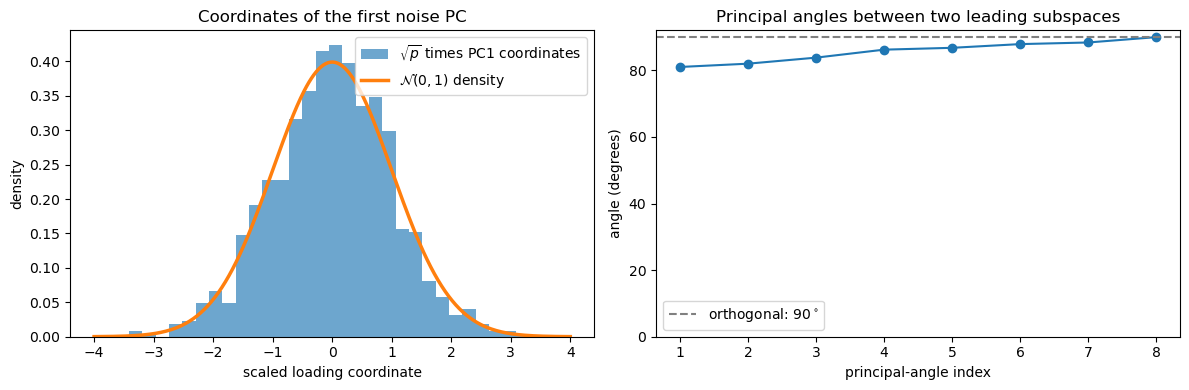

subspace overlap A_k: 0.817%
reference value k/p: 0.800%
principal angles (degrees):
[81.  82.  83.8 86.2 86.8 87.9 88.4 90. ]


In [11]:
# Generate an independent pure-noise data set of the same size.
X_noise_2 = noise_rng.normal(size=(n_samples, n_features))
X_noise_2_centered = X_noise_2 - X_noise_2.mean(axis=0)
_, _, noise_loadings_2 = np.linalg.svd(
    X_noise_2_centered, full_matrices=False
)

n_pcs_compare = 8
# Cross-Gram matrix between two leading-PC bases.
# Subspace statistics below are invariant to signs, permutations, and rotations.
cross_gram = np.einsum(
    'ip,jp->ij',
    noise_loadings[:n_pcs_compare],
    noise_loadings_2[:n_pcs_compare],
    optimize=False
)
canonical_correlations = np.linalg.svd(cross_gram, compute_uv=False)
principal_angles_noise = np.degrees(np.arccos(
    np.clip(canonical_correlations, 0, 1)
))
observed_subspace_overlap = np.sum(cross_gram ** 2) / n_pcs_compare
random_subspace_overlap = n_pcs_compare / n_features

# Scale the coordinates of the first loading vector for comparison.
scaled_pc1_coordinates = np.sqrt(n_features) * noise_loadings[0]
normal_grid = np.linspace(-4, 4, 400)
standard_normal_density = (
    np.exp(-normal_grid ** 2 / 2) / np.sqrt(2 * np.pi)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(scaled_pc1_coordinates, bins=30, density=True,
             alpha=0.65, color='tab:blue',
             label=r'$\sqrt{p}$ times PC1 coordinates')
axes[0].plot(normal_grid, standard_normal_density,
             color='tab:orange', linewidth=2.5,
             label=r'$\mathcal{N}(0,1)$ density')
axes[0].set(xlabel='scaled loading coordinate', ylabel='density',
            title='Coordinates of the first noise PC')
axes[0].legend()

axes[1].plot(np.arange(1, n_pcs_compare + 1),
             principal_angles_noise, 'o-', color='tab:blue')
axes[1].axhline(90, color='gray', linestyle='--',
                label=r'orthogonal: $90^\circ$')
axes[1].set(xticks=np.arange(1, n_pcs_compare + 1),
            ylim=(0, 92), xlabel='principal-angle index',
            ylabel='angle (degrees)',
            title='Principal angles between two leading subspaces')
axes[1].legend()

plt.tight_layout()
plt.show()

print('subspace overlap A_k:',
      f'{observed_subspace_overlap:.3%}')
print('reference value k/p:',
      f'{random_subspace_overlap:.3%}')
print('principal angles (degrees):')
print(np.round(principal_angles_noise, 1))